This template contains pre filled code. be careful: the code is *not always correct* and certainly not *complete*.<br>

if you see this symbol:<br>
🚀 Exercise:<br>

that means, there is something more to do for you.

make sure to run all the code cells from top to bottom and check if your notebook still works after resetting the python runtime regularly **at least before you save and submit your work**!

In [503]:
# Import the necessary libraries:
import pandas as pd
from pandas.core.dtypes import astype

# 1. Data Transformation

In [504]:
RawStudentDatasetName = "StudentData26" #use the correct dataset name of your student data input file - without file ending!!!

In [505]:
df = pd.read_csv(RawStudentDatasetName+".csv", sep=";", decimal=".") # change sep and decimal according to your data format
df

,How old are you?,How far do you currently live from Campus Hagenberg? (in km),How are you coming to Hagenberg?,How long does it take you on average to get from your current home to Hagenberg? (in min),How good do you rate your creative skills?,What languages do you speak? Use a comma to separate several languages.,List one of your favorite hobbies!
0,20,11,Car,11,4,German; English; Romanian; Italian,Drawing
1,21,200km,car,140,3,german; english; polish,work out
2,23,30km,bus; train,40,4,german; english; vietnamese,crochet; gaming; sewing; reading; doom scrolling
3,19,178,Zug,300,4,Deutsch; Englisch; Spanisch,Geschichte lernen
4,19,0,bus; train,130,4,German; Italian; English,listening to music
...,...,...,...,...,...,...,...
70,20,30,Bus,50 m,4,"Englisch, Spanish",Videogames
71,20,0.1,Walking,5,4,"Albanian, English",playing the violin
72,19,0.01,I live in the dorm in Hagenberg,3,4,"Serbian, English, a little German",painting
73,21,3,Car,5,3,"German,English",working out


## 1.1 Data Cleaning

### Rename columns for better readability

In [506]:
df = df.rename(columns={"How old are you?": "age",
                            "How far do you currently live from Campus Hagenberg? (in km)": "distance",
                            "How are you coming to Hagenberg?": "transportation",
                            "How long does it take you on average to get from your current home to Hagenberg? (in min)": "duration",
                            "How good do you rate your creative skills?": "creative skills",
                            "What languages do you speak? Use a comma to separate several languages.": "languages",
                            "List one of your favorite hobbies!": "hobbies"
                        })
df

,age,distance,transportation,duration,creative skills,languages,hobbies
0,20,11,Car,11,4,German; English; Romanian; Italian,Drawing
1,21,200km,car,140,3,german; english; polish,work out
2,23,30km,bus; train,40,4,german; english; vietnamese,crochet; gaming; sewing; reading; doom scrolling
3,19,178,Zug,300,4,Deutsch; Englisch; Spanisch,Geschichte lernen
4,19,0,bus; train,130,4,German; Italian; English,listening to music
...,...,...,...,...,...,...,...
70,20,30,Bus,50 m,4,"Englisch, Spanish",Videogames
71,20,0.1,Walking,5,4,"Albanian, English",playing the violin
72,19,0.01,I live in the dorm in Hagenberg,3,4,"Serbian, English, a little German",painting
73,21,3,Car,5,3,"German,English",working out


🚀 Exercise: Correction of redundant values or typing errors.<br>
some examples are already there. Scan the data if this is sufficient and change/remove/replace/add your own.

In [507]:
df = df.drop([16, 52, 53])

In [508]:
df.iloc[62] # fucking NULL value gets read as NaN

age                                                               19
distance                                                        0.05
transportation                                                   NaN
duration                                                           1
creative skills                                                    5
languages          Serbian, English, Croatian, Bosnian, Montenegr...
hobbies                                                       Gaming
Name: 65, dtype: str

In [509]:
# Remove unnecessary text characters and blanks:

df.loc[df.distance.str.contains("0.8 meters", regex=False), 'distance'] = '0.08'
df["distance"] = df["distance"].str.replace('km','')
df["distance"] = df["distance"].str.replace('m','')
df["distance"] = df["distance"].str.replace('-','')
df["distance"] = df["distance"].str.replace(',','.')
df["distance"] = df["distance"].str.strip()
df.loc[df.distance.str.contains("31.J�n", regex=False), 'distance'] = '31.1' #what???
df.loc[df.distance.str.contains("10;500", regex=False), 'distance'] = '10.5' #idk?
df.loc[df.distance.str.contains("0;55", regex=False), 'distance'] = '0.55' #idk?


df["age"] = df["age"].str.replace(' ','')

#replace 'wrong' units
df.loc[df.duration.str.contains("3h 30min", regex=False), 'duration'] = '210'
df.loc[df.duration.str.contains("with Öffis 3 1/2 hours; with car: around 2 Hours", regex=False), 'duration'] = '90'
df.loc[df.duration.str.contains("1h (Car); 2h 15min (Bus + Train)", regex=False), 'duration'] = '90'
df.loc[df.duration.str.contains("1;800 min", regex=False), 'duration'] = '18' #probably BSing so im assuming 18 minutes and 10.5km idk

df.loc[df.duration.str.contains("0, because i already live in hagenberg", regex=False), 'duration'] = '0'

df["duration"] = df["duration"].str.replace('min','')
df["duration"] = df["duration"].str.replace('m','')
df["duration"] = df["duration"].str.replace('km','')
df["duration"] = df["duration"].str.replace('+','')
df["duration"] = df["duration"].str.replace('5h','300')
df["duration"] = df["duration"].str.strip()

#Consistant Capitalisation of Languages:
df["languages"] = df["languages"].str.replace('english','English')
df["languages"] = df["languages"].str.replace('polish','Polish')
df["languages"] = df["languages"].str.replace('german','German')
df["languages"] = df["languages"].str.replace('spanish','Spanish')


#remove language levels:
df["languages"] = df["languages"].str.lower()
df["languages"] = df["languages"].str.replace('b2','')
df["languages"] = df["languages"].str.replace('b1','')
df["languages"] = df["languages"].str.replace('a2','')
df["languages"] = df["languages"].str.replace('a1.1','')
df["languages"] = df["languages"].str.replace('a1.2','')
df["languages"] = df["languages"].str.replace('muttersprache','')
df["languages"] = df["languages"].str.replace('m2','')
df["languages"] = df["languages"].str.replace('a little','')
df["languages"] = df["languages"].str.replace('bit of','')
df["languages"] = df["languages"].str.replace('fluent','')
df["languages"] = df["languages"].str.replace('mother tongue','')
df["languages"] = df["languages"].str.replace('and','')
df["languages"] = df["languages"].str.replace('level','')
df["languages"] = df["languages"].str.replace('-','')

#treat Languages in parentheses as own entries:
df["languages"] = df["languages"].str.replace('(','')
df["languages"] = df["languages"].str.replace(')','')

#remove leading and trailing whitespace:
df["languages"] = df["languages"].str.strip()

df["transportation"] = df["transportation"].str.lower()
df["transportation"] = df["transportation"].str.replace(' ','')
df.loc[df.transportation.str.contains("bus"), 'transportation'] = 'public transportation'
df.loc[df.transportation.str.contains("auto"), 'transportation'] = 'car'
df.loc[df.transportation.str.contains("train"), 'transportation'] = 'public transportation'
df.loc[df.transportation.str.contains("public"), 'transportation'] = 'public transportation'
df.loc[df.transportation.str.contains("zug"), 'transportation'] = 'public transportation'
df.loc[df.transportation.str.contains("foot"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("fuß"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("dorm"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("hagenberg"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("walk"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("leg"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("exchange"), 'transportation'] = 'on foot'
df.loc[df.transportation.str.contains("car"), 'transportation'] = 'car'
df.loc[df.transportation.str.contains("-"), 'transportation'] = 'on foot'
df = df.fillna(value="on foot")

#show data:
df

,age,distance,transportation,duration,creative skills,languages,hobbies
0,20,11,car,11,4,german; english; romanian; italian,Drawing
1,21,200,car,140,3,german; english; polish,work out
2,23,30,public transportation,40,4,german; english; vietnamese,crochet; gaming; sewing; reading; doom scrolling
3,19,178,public transportation,300,4,deutsch; englisch; spanisch,Geschichte lernen
4,19,0,public transportation,130,4,german; italian; english,listening to music
...,...,...,...,...,...,...,...
70,20,30,public transportation,50,4,"englisch, spanish",Videogames
71,20,0.1,on foot,5,4,"albanian, english",playing the violin
72,19,0.01,on foot,3,4,"serbian, english, german",painting
73,21,3,car,5,3,"german,english",working out


### Adjusting the data types


In [510]:
df.dtypes

age                str
distance           str
transportation     str
duration           str
creative skills    str
languages          str
hobbies            str
dtype: object

 🚀 Exercise: Many data types exist as strings (objects). To use quantative and temporal data for visualization, these must first be converted:

In [511]:
df.iloc[16]

age                                      23
distance                                  0
transportation                      on foot
duration                                  2
creative skills                           4
languages          english, polish, spanish
hobbies                           swimming 
Name: 17, dtype: str

In [512]:
#convert data to correct types
df.age = df.age.astype(int)
df.distance = df.distance.astype(float)
df["creative skills"] = df["creative skills"].astype(int)
df.duration = df.duration.astype(float)


In [513]:
df.dtypes


age                  int64
distance           float64
transportation         str
duration           float64
creative skills      int64
languages              str
hobbies                str
dtype: object

## 2.2 Granularity and derivation of new attributes

### Changing the granularity of a date format

The attribute types can also be subsequently modified (e.g. converting quantitative data into ordinal classes) if this helps to answer the questions.
The DateTime format alone offers numerous options for expressing dates as years, weeks, days, hours, etc.
This [page](https://pandas.pydata.org/docs/user_guide/timeseries.html#time-date-components) gives an overview of possible options, such as `year`, `month`, `day`, `hour`, `minute`, `second`, `date`, `time`, `timetz`, `dayofyear`, `weekofyear`.

For example, Timestamp can be converted to the date:

In [514]:
# df["Timestamp"].dt.date

# we don't have a timestamp here so

### Conversion of quantitative attributes into ordinal classes

One method is to use `loc` to access certain defined areas and define ordinal categories:

In [515]:
df.loc[df['distance'].between(df['distance'].min(), 10, 'both'), 'distance_cat'] = 'near'
df.loc[df['distance'].between(10, 20, 'right'), 'distance_cat'] = 'medium'
df.loc[df['distance'].between(20, 100, 'right'), 'distance_cat'] = 'far'
df.loc[df['distance'].between(100, df['distance'].max(), 'right'), 'distance_cat'] = 'far far away'

Convert integer to Likert scale meaning

In [516]:
df.loc[df['creative skills'] == 1, 'Creativity'] = 'not really'
df.loc[df['creative skills'] == 2, 'Creativity'] = 'some'
df.loc[df['creative skills'] == 3, 'Creativity'] = 'medium'
df.loc[df['creative skills'] == 4, 'Creativity'] = 'good'
df.loc[df['creative skills'] == 5, 'Creativity'] = 'very good'

In [517]:
# export csv
df.to_csv(RawStudentDatasetName+"_cleaned.csv", index=False)    #By setting index=False the row index labels are not saved in the spreadsheet

# 2. Visualization of the dataset

 🚀 For the following exercises make sure that:

 🔳 Each chart is correctly annotated (Title, Axes, Legend, Units)
 
 🔳 Use correct data types (nominal, ordinal, quantitative) and corresponding visual channels (see lecture notes)
 
 🔳 Categories are sorted meaningfully if necessary

In [518]:
import altair as alt
import seaborn as sns

🚀 Exercise: create a scatterplot to correlate distance and duration with Altair. Use color to encode the means of transportation!

In [519]:
alt.Chart(df).mark_point().encode(
    alt.X('distance'),
    alt.Y('duration'),
    alt.Color('transportation:N')
)

alt.Chart(...)

🚀 Exercise: create a scatterplot to correlate distance and duration with Seaborn. Use color to encode the means of transportation!

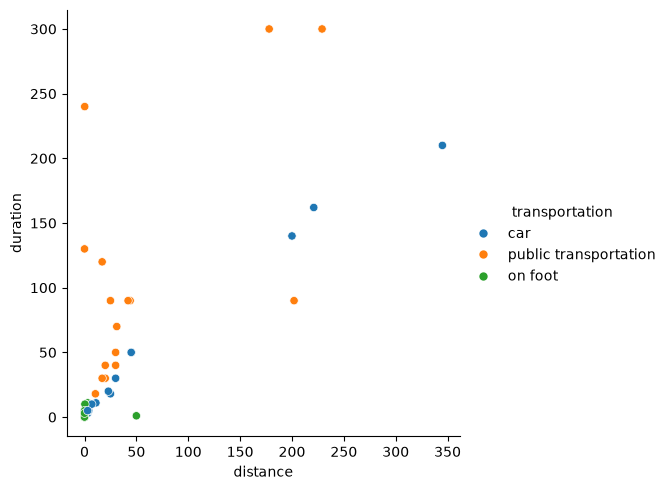

In [520]:
sns.relplot(x="distance", y="duration", data=df, kind="scatter", hue="transportation");


🚀 Exercise: Instead of using a nominal color channel use an ordered color scheme and visualize the ordered distance categories in a scatterplot in altair:

In [521]:
order = ["near", "medium", "far", "far far away"]

alt.Chart(df).mark_point().encode(
    alt.X('distance_cat:O', sort=order),
    alt.Y('duration:Q'),
    alt.Color('distance_cat:O',
              sort=order)
)

# i'm a bit confused if we should use alt.X('distance') here as well? would make more sense?

alt.Chart(...)

🚀 Exercise: Instead of using a nominal color channel use an ordered color scheme and visualize the ordered distance categories in a scatterplot in seaborn:

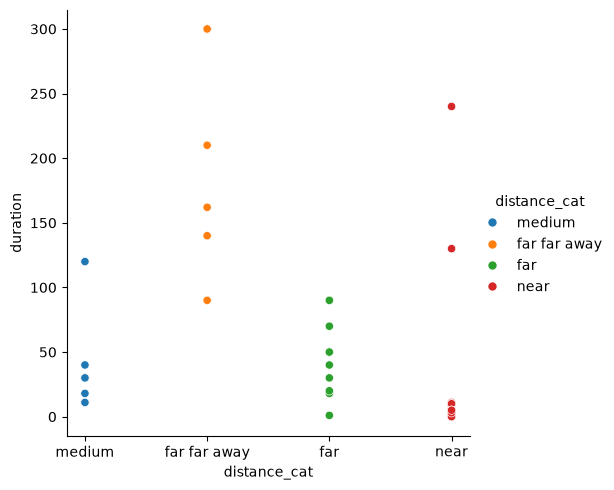

In [522]:
sns.relplot(x="distance_cat", y="duration", data=df, kind="scatter", hue="distance_cat");


🚀 Exercise: create a bar chart with Altair and visualize the means of transportation on the y-axis and the average age on the x-axis, sort by age:

In [523]:
alt.Chart(df).mark_bar(color='firebrick').encode(
    alt.X('average(age)'),
    alt.Y('transportation:N', sort='x')
)

alt.Chart(...)

🚀 Exercise: create a bar chart with Seaborn and visualize the means of transportation on the y-axis and the average age on the x-axis, sort by age:

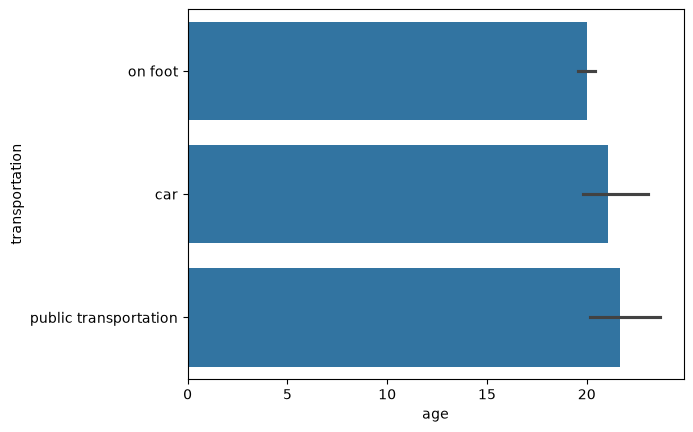

In [524]:
import numpy as np
sns.barplot(y="transportation", x="age", data=df, estimator=np.mean, order=df.groupby('transportation')['age'].mean().sort_values(ascending=True).index);

I have to say, I currently vastly prefer Altair.